In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import f_oneway
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [2]:
df_estat_bovino_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_sudeste.parquet')
df_estat_bovino_se_infecto = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_doenças_SE_infecto.parquet')
df_estat_bovino_abate_sudeste = pd.read_parquet('C:/Users/thami/OneDrive/Desktop/Projeto PPDI/Dados/tratados/bovino_bubalinos_abate_se.parquet')
#print(df_estat_bovino_sudeste.head())
#print(df_estat_bovino_se_infecto.head())
#print(df_estat_bovino_abate_sudeste.head())

In [3]:
df_estat_bovino_sudeste["MES_ANO"] = pd.to_datetime(df_estat_bovino_sudeste["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_bovino_sudeste["ANO"] = df_estat_bovino_sudeste["MES_ANO"].dt.year
print(df_estat_bovino_sudeste.head(3))

     MES_ANO UF_PROCEDENCIA ESPECIE  \
0 2021-12-01             SP  Bovino   
1 2023-09-01             SP  Bovino   
2 2021-08-01             SP  Bovino   

                                     DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  \
0  material especificado de risco (inutilização)                      45077   
1  material especificado de risco (inutilização)                      39842   
2  material especificado de risco (inutilização)                      39043   

    ANO  
0  2021  
1  2023  
2  2021  


In [4]:
df_estat_bovino_sudeste["MES_ANO"] = pd.to_datetime(df_estat_bovino_sudeste["MES_ANO"], format="%m/%Y", errors='coerce')
df_estat_bovino_sudeste["MES"] = df_estat_bovino_sudeste["MES_ANO"].dt.month
print(df_estat_bovino_sudeste.head(3))

     MES_ANO UF_PROCEDENCIA ESPECIE  \
0 2021-12-01             SP  Bovino   
1 2023-09-01             SP  Bovino   
2 2021-08-01             SP  Bovino   

                                     DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  \
0  material especificado de risco (inutilização)                      45077   
1  material especificado de risco (inutilização)                      39842   
2  material especificado de risco (inutilização)                      39043   

    ANO  MES  
0  2021   12  
1  2023    9  
2  2021    8  


In [5]:
df_estat_bovino_sudeste = df_estat_bovino_sudeste[df_estat_bovino_sudeste['ANO'].isin(range(2006, 2027))]

In [6]:
df_estat_bovino_abate_sudeste_bov = df_estat_bovino_abate_sudeste[df_estat_bovino_abate_sudeste['ESPECIE'].isin(['Bovino']) & df_estat_bovino_abate_sudeste['ANO'].isin([2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021, 2022, 2023, 2024, 2025, 2026])]
print(df_estat_bovino_abate_sudeste_bov)

         ANO  MES UF_PROCEDENCIA MUNICIPIO_PROCEDENCIA     CATEGORIA ESPECIE  \
0       2021    3             SP               Platina        Bovino  Bovino   
1       2021    9             SP                Guarei        Bovino  Bovino   
2       2021    5             SP      Presidente Alves        Bovino  Bovino   
3       2021    5             SP               Marilia        Bovino  Bovino   
4       2021    7             SP               Platina        Bovino  Bovino   
...      ...  ...            ...                   ...           ...     ...   
524085  2020    7             MG         Bueno Brandão  Bovino Femea  Bovino   
524086  2020    7             SP             Itirapina  Bovino Macho  Bovino   
524087  2020    7             MG         Montes Claros  Bovino Macho  Bovino   
524088  2020    7             MG                Piumhi  Bovino Macho  Bovino   
524089  2020    7             MG               Inhaúma  Bovino Femea  Bovino   

                 Sexo  QUANTIDADE  
0  

In [7]:
df_estat_bovino_sudeste.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17702 entries, 0 to 19247
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   MES_ANO                    17702 non-null  datetime64[ns]
 1   UF_PROCEDENCIA             17702 non-null  object        
 2   ESPECIE                    17702 non-null  object        
 3   DIAGNOSTICO                17702 non-null  object        
 4   NUMERO_ANIMAIS_ACOMETIDOS  17702 non-null  int64         
 5   ANO                        17702 non-null  int32         
 6   MES                        17702 non-null  int32         
dtypes: datetime64[ns](1), int32(2), int64(1), object(3)
memory usage: 968.1+ KB


In [8]:
df_estat_bovino_abate_sudeste_bov.info()

<class 'pandas.core.frame.DataFrame'>
Index: 462838 entries, 0 to 524089
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   ANO                    462838 non-null  int64 
 1   MES                    462838 non-null  int64 
 2   UF_PROCEDENCIA         462838 non-null  object
 3   MUNICIPIO_PROCEDENCIA  462838 non-null  object
 4   CATEGORIA              462838 non-null  object
 5   ESPECIE                462838 non-null  object
 6   Sexo                   462838 non-null  object
 7   QUANTIDADE             462838 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 31.8+ MB


<h2>Taxas de condenação/abate por estado</h2>

In [9]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste.groupby(["UF_PROCEDENCIA"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_estado = pd.DataFrame({
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_estado

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
3,SP,46284419,4390649,9.49
1,MG,43253598,1552418,3.59
0,ES,3203022,111110,3.47
2,RJ,429562,32112,7.48


<h2>Taxas de condenação/abate por ano</h2>

In [10]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["ANO"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste.groupby(["ANO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"] * 100, 2
)

tabela_abatidocondenado_ano = pd.DataFrame({
    "ANO": abatidos["ANO"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_ano

,ANO,Abatidos,Condenados,Percentual Condenados
0,2006,4092818,136411,3.33
1,2007,4713633,127447,2.70
2,2008,4645047,118404,2.55
3,2009,4066043,104655,2.57
4,2010,4099399,114902,2.80
5,2011,3656908,104144,2.85
6,2012,3867125,102534,2.65
7,2013,4618327,109984,2.38
8,2014,4990477,122151,2.45
9,2015,4381338,111208,2.54


<h2>Taxas de condenação/abate por estado</h2>
<h3>Qual estado teve a maior taxa com base no total de abate</h3>

In [11]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["UF_PROCEDENCIA"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste.groupby(["UF_PROCEDENCIA"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"].sum() * 100, 2
)

tabela_abatidocondenado_estado = pd.DataFrame({
    "UF_PROCEDENCIA": abatidos["UF_PROCEDENCIA"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_estado

,UF_PROCEDENCIA,Abatidos,Condenados,Percentual Condenados
3,SP,46284419,4390649,4.71
1,MG,43253598,1552418,1.67
0,ES,3203022,111110,0.12
2,RJ,429562,32112,0.03


<h2>Taxas de condenação/abate por ano</h2>
<h3>Qual ano teve a maior taxa com base no total de abate</h3>

In [12]:
abatidos = (
    df_estat_bovino_abate_sudeste_bov.groupby(["ANO"], as_index=False)["QUANTIDADE"]
      .sum()
      .sort_values("QUANTIDADE", ascending=False)
)

condenados = (
    df_estat_bovino_sudeste.groupby(["ANO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

perc_abatidocondenado = round(
    condenados["NUMERO_ANIMAIS_ACOMETIDOS"] /
    abatidos["QUANTIDADE"].sum() * 100, 2
)

tabela_abatidocondenado_anototal = pd.DataFrame({
    "ANO": abatidos["ANO"],
    "Abatidos": abatidos["QUANTIDADE"],
    "Condenados": condenados["NUMERO_ANIMAIS_ACOMETIDOS"],
    "Percentual Condenados": perc_abatidocondenado
})

tabela_abatidocondenado_anototal

,ANO,Abatidos,Condenados,Percentual Condenados
0,2006,4092818,136411,0.15
1,2007,4713633,127447,0.14
2,2008,4645047,118404,0.13
3,2009,4066043,104655,0.11
4,2010,4099399,114902,0.12
5,2011,3656908,104144,0.11
6,2012,3867125,102534,0.11
7,2013,4618327,109984,0.12
8,2014,4990477,122151,0.13
9,2015,4381338,111208,0.12


<h3>Teste anova e tukey<h3>

In [13]:
condenacao_consolidado = df_estat_bovino_sudeste.groupby(['ANO', 'UF_PROCEDENCIA'], as_index=False).agg(CONDENADO=("NUMERO_ANIMAIS_ACOMETIDOS", "sum"))
condenacao_consolidado

,ANO,UF_PROCEDENCIA,CONDENADO
0,2006,ES,900
1,2006,MG,8978
2,2006,SP,126533
3,2007,ES,1015
4,2007,MG,8201
...,...,...,...
64,2025,SP,473970
65,2026,ES,3658
66,2026,MG,33396
67,2026,RJ,1837


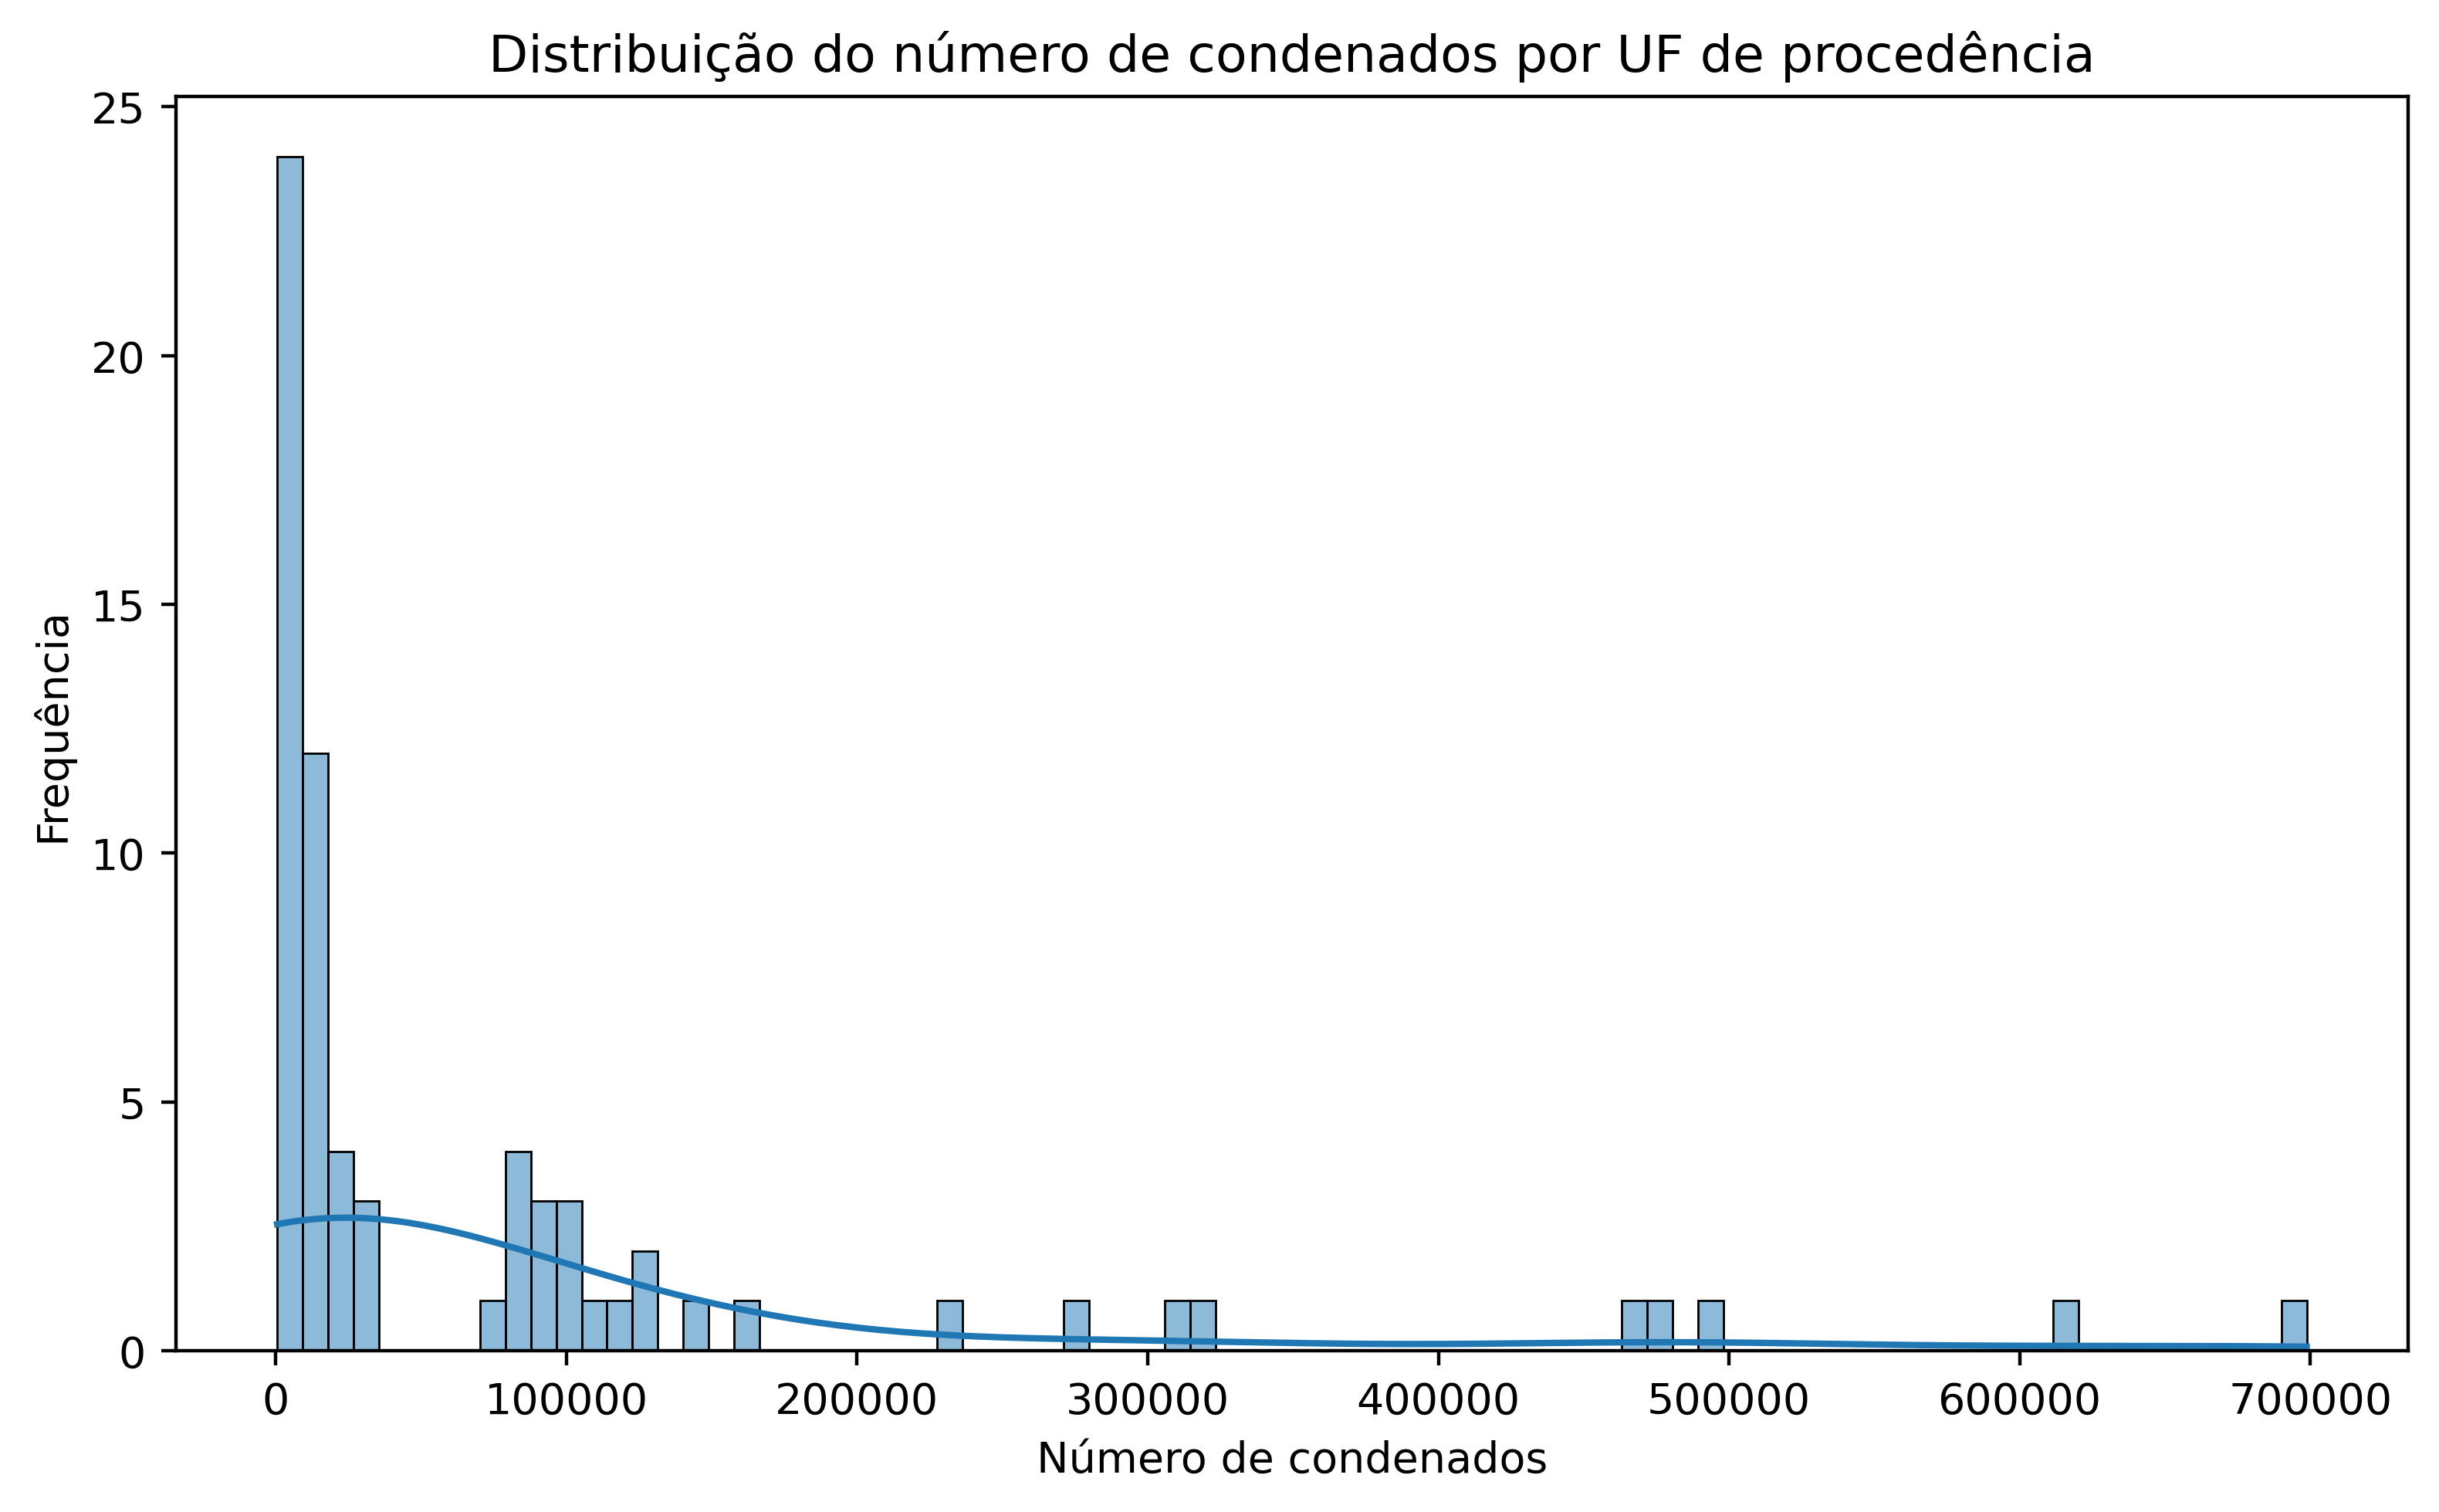

In [14]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=condenacao_consolidado,
    x="CONDENADO",
    bins=80,
    kde=True
)

pl.title("Distribuição do número de condenados por UF de procedência")
pl.xlabel("Número de condenados")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [15]:
abate_consolidado = df_estat_bovino_abate_sudeste_bov.groupby(['ANO', 'UF_PROCEDENCIA'], as_index=False).agg(ABATE=("QUANTIDADE", "sum"))
abate_consolidado

,ANO,UF_PROCEDENCIA,ABATE
0,2006,ES,204976
1,2006,MG,1504241
2,2006,RJ,11830
3,2006,SP,2371771
4,2007,ES,217736
...,...,...,...
79,2025,SP,3114344
80,2026,ES,35968
81,2026,MG,1880426
82,2026,RJ,11937


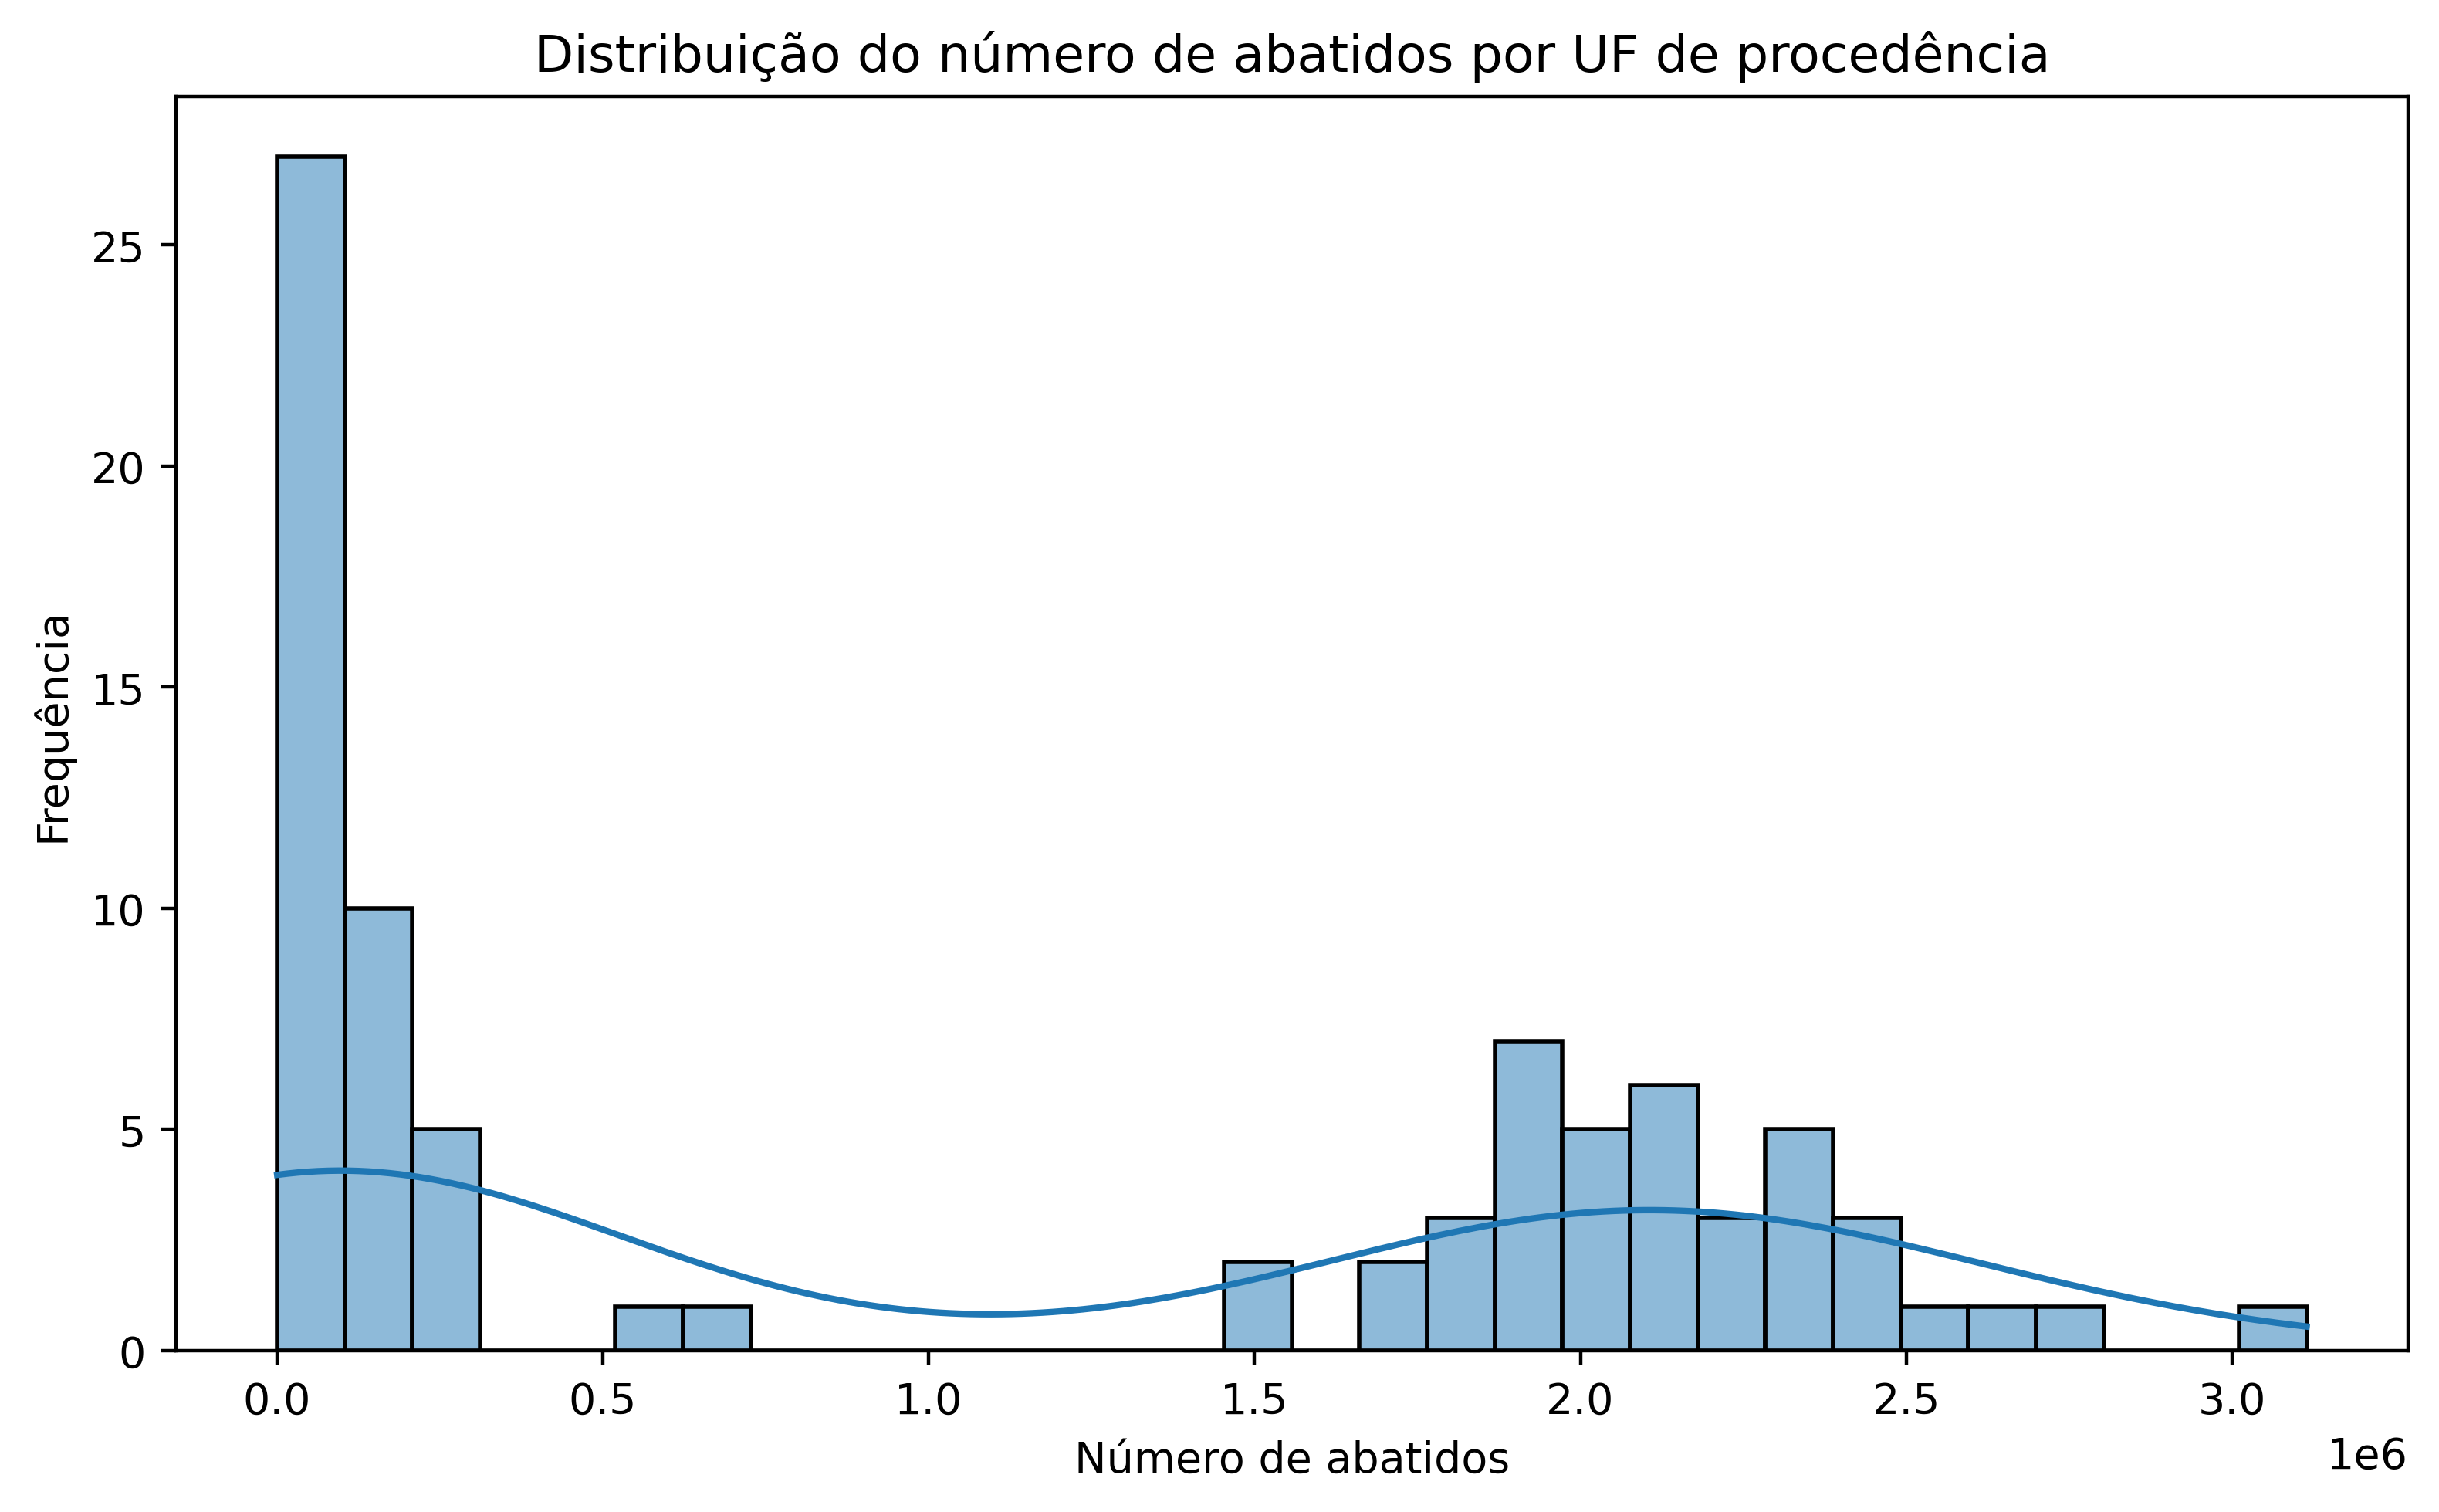

In [17]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=abate_consolidado,
    x="ABATE",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de abatidos por UF de procedência")
pl.xlabel("Número de abatidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()

In [18]:
dados_anova = pd.merge(condenacao_consolidado, abate_consolidado, on=['ANO', 'UF_PROCEDENCIA'], how='right', validate='one_to_one')
dados_anova["percentual_condenados"] = (
    dados_anova["CONDENADO"] / dados_anova["ABATE"] * 100
).fillna(0)

#dados_anova["ABATE"] = dados_anova["ABATE"].fillna(0)
dados_anova["CONDENADO"] = dados_anova["CONDENADO"].fillna(0)

print(dados_anova.head(100))
dados_anova.to_excel("tabela_dadosanova.xlsx", index=False)



     ANO UF_PROCEDENCIA  CONDENADO    ABATE  percentual_condenados
0   2006             ES      900.0   204976               0.439076
1   2006             MG     8978.0  1504241               0.596846
2   2006             RJ        0.0    11830               0.000000
3   2006             SP   126533.0  2371771               5.334959
4   2007             ES     1015.0   217736               0.466161
..   ...            ...        ...      ...                    ...
79  2025             SP   473970.0  3114364              15.218838
80  2026             ES     3658.0    12813              28.549130
81  2026             MG    33396.0   526693               6.340696
82  2026             RJ     1837.0     5071              36.225597
83  2026             SP   109757.0   711599              15.423996

[84 rows x 5 columns]


In [16]:
# 1. Garante padronização das chaves antes de cruzar
for df in [condenacao_consolidado, abate_consolidado]:
    df["ANO"] = df["ANO"].astype(int)
    df["UF_PROCEDENCIA"] = df["UF_PROCEDENCIA"].astype(str).str.strip().str.upper()

# 2. Usa how='inner' para não transformar anos sem base de condenação em 0% falso
dados_anova = pd.merge(
    condenacao_consolidado,
    abate_consolidado,
    on=["ANO", "UF_PROCEDENCIA"],
    how="inner",
    validate="one_to_one"
)

# 3. Remove eventuais registros com abate zerado para evitar divisão por zero (inf)
dados_anova = dados_anova[dados_anova["ABATE"] > 0].copy()

# 4. Preenche nulos e calcula o percentual
dados_anova["CONDENADO"] = dados_anova["CONDENADO"].fillna(0)
dados_anova["percentual_condenados"] = (
    dados_anova["CONDENADO"] / dados_anova["ABATE"] * 100
).round(4)

# 5. Organiza a ordem das colunas e ordena por Ano e UF
colunas_ordenadas = ["ANO", "UF_PROCEDENCIA", "ABATE", "CONDENADO", "percentual_condenados"]
dados_anova = (
    dados_anova[colunas_ordenadas]
    .sort_values(["ANO", "UF_PROCEDENCIA"])
    .reset_index(drop=True)
)

print(dados_anova.head(100))
dados_anova.to_excel("tabela_dadosanova.xlsx", index=False)

     ANO UF_PROCEDENCIA    ABATE  CONDENADO  percentual_condenados
0   2006             ES   204976        900                 0.4391
1   2006             MG  1504241       8978                 0.5968
2   2006             SP  2371771     126533                 5.3350
3   2007             ES   217736       1015                 0.4662
4   2007             MG  1945002       8201                 0.4216
..   ...            ...      ...        ...                    ...
64  2025             SP  3114344     473970                15.2189
65  2026             ES    35968       3658                10.1702
66  2026             MG  1880426      33396                 1.7760
67  2026             RJ    11937       1837                15.3891
68  2026             SP  2404947     109757                 4.5638

[69 rows x 5 columns]


In [19]:
grupos = [
    grupo["percentual_condenados"].dropna()
    for _, grupo in dados_anova.groupby("UF_PROCEDENCIA")
]


In [20]:
f_stat, p_value = stats.f_oneway(*grupos)
print("F =", f_stat)
print("p =", p_value)

F = 1.237492605224286
p = 0.3016515466704281


In [21]:
modelo = ols('percentual_condenados ~ C(UF_PROCEDENCIA)', data=dados_anova).fit()
anova_tabela = sm.stats.anova_lm(modelo, typ=2)
print(anova_tabela)


                        sum_sq    df         F    PR(>F)
C(UF_PROCEDENCIA)   362.145457   3.0  1.237493  0.301652
Residual           7803.854460  80.0       NaN       NaN


In [22]:
grupos_A = [
    grupo["percentual_condenados"].dropna()
    for _, grupo in dados_anova.groupby("ANO")
]

In [23]:
f_stat, p_value = stats.f_oneway(*grupos_A)
print("F =", f_stat)
print("p =", p_value)

F = 9.129673283767222
p = 5.792070229534477e-12


In [24]:
modelo = ols('percentual_condenados ~ C(ANO) + C(UF_PROCEDENCIA)', data=dados_anova).fit()
anova_tabela = sm.stats.anova_lm(modelo, typ=2)
print(anova_tabela)

                        sum_sq    df          F        PR(>F)
C(ANO)             6071.245509  20.0  10.512318  5.938887e-13
C(UF_PROCEDENCIA)   362.145457   3.0   4.180348  9.388970e-03
Residual           1732.608951  60.0        NaN           NaN


In [25]:
#se for p<0.05, realizar o teste de Tukey para comparações múltiplas
tukey = pairwise_tukeyhsd(
    endog=dados_anova["percentual_condenados"],
    groups=dados_anova["UF_PROCEDENCIA"],
    alpha=0.05
)

#print(tukey)

In [26]:
grupo_sp = dados_anova[dados_anova['UF_PROCEDENCIA'] == 'SP']
grupo_sp

,ANO,UF_PROCEDENCIA,CONDENADO,ABATE,percentual_condenados
3,2006,SP,126533.0,2371771,5.334959
7,2007,SP,118231.0,2523877,4.684499
11,2008,SP,104531.0,2197224,4.757412
15,2009,SP,90439.0,1963172,4.606779
19,2010,SP,99477.0,2029040,4.902663
23,2011,SP,91336.0,1927020,4.739754
27,2012,SP,87492.0,1971751,4.437274
31,2013,SP,91096.0,2018082,4.513989
35,2014,SP,101534.0,2108606,4.815219
39,2015,SP,87613.0,1764749,4.964615


In [27]:
grupo_mg = dados_anova[dados_anova['UF_PROCEDENCIA'] == 'MG']
grupo_sp = dados_anova[dados_anova['UF_PROCEDENCIA'] == 'SP']
grupo_es = dados_anova[dados_anova['UF_PROCEDENCIA'] == 'ES']
grupo_rj = dados_anova[dados_anova['UF_PROCEDENCIA'] == 'RJ']

In [28]:
stat, p_valor = stats.mannwhitneyu(grupo_sp['ABATE'], grupo_mg['ABATE'], alternative='two-sided')
print(f'Estatística U: {stat:.2f}, p-valor: {p_valor:.4f}')
#https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html

Estatística U: 257.00, p-valor: 0.3651


In [29]:
stat, p_valor = stats.mannwhitneyu(grupo_sp['ABATE'], grupo_es['ABATE'], alternative='two-sided')
print(f'Estatística U: {stat:.2f}, p-valor: {p_valor:.4f}')

Estatística U: 441.00, p-valor: 0.0000


In [30]:
stat, p_valor = stats.mannwhitneyu(grupo_sp['ABATE'], grupo_rj['ABATE'], alternative='two-sided')
print(f'Estatística U: {stat:.2f}, p-valor: {p_valor:.4f}')

Estatística U: 441.00, p-valor: 0.0000


In [31]:
stat, p_valor = stats.mannwhitneyu(grupo_mg['ABATE'], grupo_es['ABATE'], alternative='two-sided')
print(f'Estatística U: {stat:.2f}, p-valor: {p_valor:.4f}')

Estatística U: 441.00, p-valor: 0.0000


In [32]:
stat, p_valor = stats.mannwhitneyu(grupo_mg['ABATE'], grupo_rj['ABATE'], alternative='two-sided')
print(f'Estatística U: {stat:.2f}, p-valor: {p_valor:.4f}')

Estatística U: 441.00, p-valor: 0.0000


In [33]:
stat, p_valor = stats.mannwhitneyu(grupo_rj['ABATE'], grupo_es['ABATE'], alternative='two-sided')
print(f'Estatística U: {stat:.2f}, p-valor: {p_valor:.4f}')

Estatística U: 15.00, p-valor: 0.0000


In [34]:
modelo = smf.glm(
    "CONDENADO + I(ABATE - CONDENADO) ~ C(UF_PROCEDENCIA) + C(ANO)",
    data=dados_anova,
    family=sm.families.Binomial()
).fit()

print(modelo.summary())

                           Generalized Linear Model Regression Results                           
Dep. Variable:     ['CONDENADO', 'I(ABATE - CONDENADO)']   No. Observations:                   84
Model:                                               GLM   Df Residuals:                       60
Model Family:                                   Binomial   Df Model:                           23
Link Function:                                     Logit   Scale:                          1.0000
Method:                                             IRLS   Log-Likelihood:            -2.0422e+05
Date:                                   Mon, 17 Aug 2026   Deviance:                   4.0764e+05
Time:                                           14:15:14   Pearson chi2:                 3.95e+05
No. Iterations:                                        7   Pseudo R-squ. (CS):              1.000
Covariance Type:                               nonrobust                                         
                    

In [35]:
#kruskal-wallis test
estatistica, p_valor = stats.kruskal(
    grupo_sp,
    grupo_mg,
    grupo_es,
    grupo_rj
)
print(estatistica)
print(p_valor)

[2.84822670e-14 8.30000000e+01 6.46317654e+01 6.92316126e+01
 1.78012083e+01]
[1.00000000e+00 6.97267035e-18 6.01344899e-14 6.23420521e-15
 4.83384157e-04]


In [36]:
base = dados_anova[["ANO", "UF_PROCEDENCIA", "percentual_condenados"]].dropna()
painel = (
    base
    .pivot(index="ANO", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

print(painel)

UF_PROCEDENCIA         ES         MG         RJ         SP
ANO                                                       
2006             0.439076   0.596846   0.000000   5.334959
2007             0.466161   0.421645   0.000000   4.684499
2008             0.476711   0.588398   0.000000   4.757412
2009             0.329063   0.716216   0.000000   4.606779
2010             0.486725   0.781716   0.000000   4.902663
2011             0.378084   0.782655   0.000000   4.739754
2012             0.306722   0.837266   0.000000   4.437274
2013             0.298591   0.764341   0.000000   4.513989
2014             0.216667   0.764713   0.000000   4.815219
2015             0.679881   0.932717   0.000000   4.964615
2016             0.840278   0.745396   0.000000   4.142204
2017             1.202877   0.772464   0.000000   4.458125
2018             1.218599   1.031909   0.000000   4.092901
2019             1.115508   1.188391   0.000000   5.532384
2020             1.238509   0.659583   0.000000   7.4315

In [37]:
resultado_friedman = friedmanchisquare(
    *[painel[uf] for uf in painel.columns]
)

print(f"Resultado do Teste de Friedman: {resultado_friedman.statistic:.4f}, p-valor: {resultado_friedman.pvalue:.4f}")

Resultado do Teste de Friedman: 31.1714, p-valor: 0.0000


há evidência de que pelo menos uma unidade federativa apresenta distribuição/mediana de percentual de condenação diferente das demais, considerando os mesmos anos.

In [38]:
resultados = []

for uf1, uf2 in combinations(painel.columns, 2):
    teste = wilcoxon(
        painel[uf1],
        painel[uf2],
        alternative="two-sided"
    )

    resultados.append({
        "UF 1": uf1,
        "UF 2": uf2,
        "estatística": teste.statistic,
        "p_valor": teste.pvalue
    })

pos_hoc = pd.DataFrame(resultados)

# Correção para os vários testes entre pares
pos_hoc["p_ajustado_holm"] = multipletests(
    pos_hoc["p_valor"],
    method="holm"
)[1]

pos_hoc["diferença_significativa"] = pos_hoc["p_ajustado_holm"] < 0.05

print(pos_hoc)

  UF 1 UF 2  estatística       p_valor  p_ajustado_holm  \
0   ES   MG         84.0  2.877340e-01         0.503420   
1   ES   RJ         75.0  1.678066e-01         0.503420   
2   ES   SP         42.0  9.016037e-03         0.045080   
3   MG   RJ         78.0  2.029171e-01         0.503420   
4   MG   SP          0.0  9.536743e-07         0.000006   
5   RJ   SP         60.0  5.469322e-02         0.218773   

   diferença_significativa  
0                    False  
1                    False  
2                     True  
3                    False  
4                     True  
5                    False  


O teste de Friedman indicou diferença entre as UFs quanto ao percentual anual de condenação (χ² = ...; p = ...). Nas comparações pós-hoc de Wilcoxon com correção de Holm, SP apresentou percentual significativamente superior ao de MG (p ajustado = ...) e ao ES (p ajustado...). As demais comparações não apresentaram diferença estatisticamente significativa (p ajustado ≥ 0,05).

In [39]:
resumo_ufs = painel.agg(["median", "mean", "std"]).T
print(resumo_ufs)

                  median      mean        std
UF_PROCEDENCIA                               
ES              0.840278  6.612961  10.206851
MG              0.782655  3.783265   5.336418
RJ              0.000000  7.856193  13.961149
SP              4.902663  9.456809   7.913398


In [40]:
pos_hoc["diferença_média_UF1_menos_UF2"] = [
    (painel[uf1] - painel[uf2]).mean()
    for uf1, uf2 in zip(pos_hoc["UF 1"], pos_hoc["UF 2"])
]

print(pos_hoc)

  UF 1 UF 2  estatística       p_valor  p_ajustado_holm  \
0   ES   MG         84.0  2.877340e-01         0.503420   
1   ES   RJ         75.0  1.678066e-01         0.503420   
2   ES   SP         42.0  9.016037e-03         0.045080   
3   MG   RJ         78.0  2.029171e-01         0.503420   
4   MG   SP          0.0  9.536743e-07         0.000006   
5   RJ   SP         60.0  5.469322e-02         0.218773   

   diferença_significativa  diferença_média_UF1_menos_UF2  
0                    False                       2.829696  
1                    False                      -1.243232  
2                     True                      -2.843848  
3                    False                      -4.072928  
4                     True                      -5.673544  
5                    False                      -1.600616  


In [41]:
tabela_descritiva = (
    dados_anova
    .groupby("UF_PROCEDENCIA")
    .agg(
        anos_analisados=("ANO", "nunique"),
        total_abatidos=("ABATE", "sum"),
        total_condenados=("CONDENADO", "sum"),
        mediana_percentual=("percentual_condenados", "median"),
        media_percentual=("percentual_condenados", "mean"),
        dp_percentual=("percentual_condenados", "std"),
        minimo_percentual=("percentual_condenados", "min"),
        maximo_percentual=("percentual_condenados", "max")
    )
    .reset_index()
)

# Percentual global da UF: total condenado ÷ total abatido
tabela_descritiva["percentual_global"] = (
    tabela_descritiva["total_condenados"]
    / tabela_descritiva["total_abatidos"]
    * 100
)

tabela_descritiva = tabela_descritiva.round(2)

print(tabela_descritiva)

  UF_PROCEDENCIA  anos_analisados  total_abatidos  total_condenados  \
0             ES               21         3179867          111110.0   
1             MG               21        41899825         1552418.0   
2             RJ               21          422696           32112.0   
3             SP               21        44591091         4390649.0   

   mediana_percentual  media_percentual  dp_percentual  minimo_percentual  \
0                0.84              6.61          10.21               0.22   
1                0.78              3.78           5.34               0.42   
2                0.00              7.86          13.96               0.00   
3                4.90              9.46           7.91               4.09   

   maximo_percentual  percentual_global  
0              28.55               3.49  
1              15.32               3.71  
2              38.36               7.60  
3              28.43               9.85  


In [42]:
print(
    f"Friedman: qui-quadrado = {resultado_friedman.statistic:.3f}; "
    f"p = {resultado_friedman.pvalue:.4f}"
)
tabela_pos_hoc = pos_hoc[
    [
        "UF 1",
        "UF 2",
        "p_valor",
        "p_ajustado_holm",
        "diferença_média_UF1_menos_UF2",
        "diferença_significativa"
    ]
].copy()

tabela_pos_hoc = tabela_pos_hoc.round(4)

print(tabela_pos_hoc)

Friedman: qui-quadrado = 31.171; p = 0.0000
  UF 1 UF 2  p_valor  p_ajustado_holm  diferença_média_UF1_menos_UF2  \
0   ES   MG   0.2877           0.5034                         2.8297   
1   ES   RJ   0.1678           0.5034                        -1.2432   
2   ES   SP   0.0090           0.0451                        -2.8438   
3   MG   RJ   0.2029           0.5034                        -4.0729   
4   MG   SP   0.0000           0.0000                        -5.6735   
5   RJ   SP   0.0547           0.2188                        -1.6006   

   diferença_significativa  
0                    False  
1                    False  
2                     True  
3                    False  
4                     True  
5                    False  


In [43]:
print(
    f"Friedman: qui-quadrado = {resultado_friedman.statistic:.3f}; "
    f"p = {resultado_friedman.pvalue:.4f}"
)

Friedman: qui-quadrado = 31.171; p = 0.0000


In [44]:
abate_consolidado_mes = df_estat_bovino_abate_sudeste_bov.groupby(['ANO', 'MES', 'UF_PROCEDENCIA'], as_index=False).agg(ABATE=("QUANTIDADE", "sum"))
abate_consolidado_mes

,ANO,MES,UF_PROCEDENCIA,ABATE
0,2006,1,ES,14517
1,2006,1,MG,111912
2,2006,1,RJ,772
3,2006,1,SP,172968
4,2006,2,ES,13028
...,...,...,...,...
950,2026,3,ES,4364
951,2026,3,MG,188057
952,2026,3,RJ,1554
953,2026,3,SP,246487


In [45]:
condenacao_consolidado_mes = df_estat_bovino_sudeste.groupby(['ANO','MES', 'UF_PROCEDENCIA'], as_index=False).agg(CONDENADO=("NUMERO_ANIMAIS_ACOMETIDOS", "sum"))
condenacao_consolidado_mes

,ANO,MES,UF_PROCEDENCIA,CONDENADO
0,2006,1,ES,72
1,2006,1,MG,1077
2,2006,1,SP,10898
3,2006,2,ES,20
4,2006,2,MG,784
...,...,...,...,...
785,2026,2,SP,33869
786,2026,3,ES,1074
787,2026,3,MG,10302
788,2026,3,RJ,566


Não use .fillna(0) no percentual diretamente, pois isso também transformaria problemas como ABATE ausente em 0%, o que pode mascarar erros.

In [46]:
dados_mes = pd.merge(condenacao_consolidado_mes, abate_consolidado_mes, on=['ANO', 'MES','UF_PROCEDENCIA'], how='left', validate='one_to_one')
dados_mes["percentual_condenados"] = (
    dados_mes["CONDENADO"] / dados_mes["ABATE"] * 100
)
dados_mes

,ANO,MES,UF_PROCEDENCIA,CONDENADO,ABATE,percentual_condenados
0,2006,1,ES,72,14517,0.495970
1,2006,1,MG,1077,111912,0.962363
2,2006,1,SP,10898,172968,6.300587
3,2006,2,ES,20,13028,0.153516
4,2006,2,MG,784,105627,0.742234
...,...,...,...,...,...,...
785,2026,2,SP,33869,224848,15.063065
786,2026,3,ES,1074,4364,24.610449
787,2026,3,MG,10302,188057,5.478126
788,2026,3,RJ,566,1554,36.422136


In [47]:
ano = 2006

painel_2006 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2006[uf] for uf in painel_2006.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(20.666666666666657), pvalue=np.float64(3.253047117267141e-05))


In [48]:
ano = 2010

painel_2010 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2010[uf] for uf in painel_2010.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(22.166666666666657), pvalue=np.float64(1.5366306526875732e-05))


In [51]:
ano = 2007

painel_2007 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2007[uf] for uf in painel_2007.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(20.181818181818187), pvalue=np.float64(4.145470838528921e-05))


In [52]:
ano = 2008

painel_2008 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2008[uf] for uf in painel_2008.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(18.666666666666657), pvalue=np.float64(8.842698865988345e-05))


In [53]:
ano = 2009

painel_2009 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2009[uf] for uf in painel_2009.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(24.0), pvalue=np.float64(6.144212353328207e-06))


In [54]:
ano = 2011

painel_2011 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2011[uf] for uf in painel_2011.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(24.0), pvalue=np.float64(6.144212353328207e-06))


In [55]:
ano = 2012

painel_2012 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2012[uf] for uf in painel_2012.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(24.0), pvalue=np.float64(6.144212353328207e-06))


In [56]:
ano = 2013

painel_2013 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2013[uf] for uf in painel_2013.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(24.0), pvalue=np.float64(6.144212353328207e-06))


In [57]:
ano = 2014

painel_2014 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2014[uf] for uf in painel_2014.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(24.0), pvalue=np.float64(6.144212353328207e-06))


In [58]:
ano = 2015

painel_2015 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2015[uf] for uf in painel_2015.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(20.666666666666657), pvalue=np.float64(3.253047117267141e-05))


teve p < 0,05

In [59]:
ano = 2016

painel_2016 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2016[uf] for uf in painel_2016.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(18.166666666666657), pvalue=np.float64(0.00011354250096044906))


In [73]:
#teste de wilcoxon com correção de holm
ano = 2016

painel_2016 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2016.columns, 2):
    teste = wilcoxon(
        painel_2016[uf1],
        painel_2016[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2016[uf1] - painel_2016[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2016    ES × MG   0.0640             0.1808  0.0640          False
1  2016    ES × SP   0.0005            -3.5440  0.0015           True
2  2016    MG × SP   0.0005            -3.6600  0.0015           True


In [87]:
ano_16 = 2016

resumo_2016 = (
    dados_mes.loc[dados_mes["ANO"] == ano_16].groupby("UF_PROCEDENCIA")
    .agg(
        total_abatidos=("ABATE", "sum"),
        total_condenados=("CONDENADO", "sum"),
        mediana_indice=("percentual_condenados", "median"),
        media_indice=("percentual_condenados", "mean")
    )
)

resumo_2016["indice_global"] = (
    resumo_2016["total_condenados"]
    / resumo_2016["total_abatidos"]
    * 100
)

print(resumo_2016)

                total_abatidos  total_condenados  mediana_indice  \
UF_PROCEDENCIA                                                     
ES                      187795              1578        0.868872   
MG                     1910797             14243        0.776848   
SP                     1785547             73961        4.429694   

                media_indice  indice_global  
UF_PROCEDENCIA                               
ES                  0.837372       0.840278  
MG                  0.742910       0.745396  
SP                  4.221553       4.142204  


In [60]:
ano = 2017

painel_2017 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2017[uf] for uf in painel_2017.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(22.166666666666657), pvalue=np.float64(1.5366306526875732e-05))


teve p < 0,05

In [61]:
ano = 2018

painel_2018 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2018[uf] for uf in painel_2018.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(18.166666666666657), pvalue=np.float64(0.00011354250096044906))


In [74]:
#teste de wilcoxon com correção de holm
ano = 2018

painel_2018 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2018.columns, 2):
    teste = wilcoxon(
        painel_2018[uf1],
        painel_2018[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2018[uf1] - painel_2018[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2018    ES × MG   0.1514             0.2820  0.1514          False
1  2018    ES × SP   0.0005            -3.0219  0.0015           True
2  2018    MG × SP   0.0005            -2.9507  0.0015           True


In [88]:
ano_18 = 2018

resumo_2018 = (
    dados_mes.loc[dados_mes["ANO"] == ano_18].groupby("UF_PROCEDENCIA")
    .agg(
        total_abatidos=("ABATE", "sum"),
        total_condenados=("CONDENADO", "sum"),
        mediana_indice=("percentual_condenados", "median"),
        media_indice=("percentual_condenados", "mean")
    )
)

resumo_2018["indice_global"] = (
    resumo_2018["total_condenados"]
    / resumo_2018["total_abatidos"]
    * 100
)

print(resumo_2018)

                total_abatidos  total_condenados  mediana_indice  \
UF_PROCEDENCIA                                                     
ES                      134827              1643        1.346744   
MG                     2280822             23536        1.050852   
SP                     2069266             84693        4.018858   

                media_indice  indice_global  
UF_PROCEDENCIA                               
ES                  1.266771       1.218599  
MG                  1.030369       1.031909  
SP                  4.124877       4.092901  


In [62]:
ano = 2019

painel_2019 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2019[uf] for uf in painel_2019.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(18.666666666666657), pvalue=np.float64(8.842698865988345e-05))


In [63]:
ano = 2020

painel_2020 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2020[uf] for uf in painel_2020.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(24.0), pvalue=np.float64(6.144212353328207e-06))


teve p < 0,05

In [64]:
ano = 2021

painel_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2021[uf] for uf in painel_2021.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(18.381818181818176), pvalue=np.float64(0.0003668748380501129))


In [90]:
ano_21 = 2021

resumo_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano_21].groupby("UF_PROCEDENCIA")
    .agg(
        total_abatidos=("ABATE", "sum"),
        total_condenados=("CONDENADO", "sum"),
        mediana_indice=("percentual_condenados", "median"),
        media_indice=("percentual_condenados", "mean")
    )
)

resumo_2021["indice_global"] = (
    resumo_2021["total_condenados"]
    / resumo_2021["total_abatidos"]
    * 100
)

print(resumo_2021)

                total_abatidos  total_condenados  mediana_indice  \
UF_PROCEDENCIA                                                     
ES                       53452             13238       26.366468   
MG                     1868397            272676       15.912492   
RJ                       30136              4233       14.056088   
SP                     2107048            466579       21.515274   

                media_indice  indice_global  
UF_PROCEDENCIA                               
ES                 25.412595      24.766145  
MG                 14.429463      14.594115  
RJ                 15.899433      14.046323  
SP                 21.916564      22.143729  


In [91]:
#teste de wilcoxon com correção de holm
ano = 2021

painel_2021 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2021.columns, 2):
    teste = wilcoxon(
        painel_2021[uf1],
        painel_2021[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2021[uf1] - painel_2021[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2021    ES × MG   0.0010             6.9884  0.0059           True
1  2021    ES × RJ   0.0049            10.1454  0.0195           True
2  2021    ES × SP   0.6377            -0.4400  1.0000          False
3  2021    MG × RJ   0.8311            -3.6912  1.0000          False
4  2021    MG × SP   0.0010            -7.6779  0.0059           True
5  2021    RJ × SP   0.0068            -6.1827  0.0205           True


teve p < 0,05

In [92]:
ano = 2022

painel_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2022[uf] for uf in painel_2022.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(21.100000000000023), pvalue=np.float64(0.00010036000453271563))


In [93]:
ano = 2022

painel_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2022.columns, 2):
    teste = wilcoxon(
        painel_2022[uf1],
        painel_2022[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2022[uf1] - painel_2022[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2022    ES × MG   0.0093             4.0904  0.0371           True
1  2022    ES × RJ   0.0771             4.9024  0.1919          False
2  2022    ES × SP   0.0640            -5.9328  0.1919          False
3  2022    MG × RJ   0.7910            -1.3475  0.7910          False
4  2022    MG × SP   0.0005           -10.2566  0.0029           True
5  2022    RJ × SP   0.0005            -9.7526  0.0029           True


In [99]:
ano_22 = 2022

resumo_2022 = (
    dados_mes.loc[dados_mes["ANO"] == ano_22].groupby("UF_PROCEDENCIA")
    .agg(
        total_abatidos=("ABATE", "sum"),
        total_condenados=("CONDENADO", "sum"),
        mediana_indice=("percentual_condenados", "median"),
        media_indice=("percentual_condenados", "mean")
    )
)

resumo_2022["indice_global"] = (
    resumo_2022["total_condenados"]
    / resumo_2022["total_abatidos"]
    * 100
)

print(resumo_2022)

                total_abatidos  total_condenados  mediana_indice  \
UF_PROCEDENCIA                                                     
ES                       72742             13219       18.576300   
MG                     2036646            309990       14.689067   
RJ                       27964              3816       16.635284   
SP                     2408026            618900       25.954413   

                media_indice  indice_global  
UF_PROCEDENCIA                               
ES                 21.453324      18.172445  
MG                 15.382085      15.220613  
RJ                 16.161298      13.646116  
SP                 25.767189      25.701550  


In [94]:
ano = 2023

painel_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2023[uf] for uf in painel_2023.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(19.30000000000001), pvalue=np.float64(0.0002369982071871208))


In [95]:
ano = 2023

painel_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultados = []

for uf1, uf2 in combinations(painel_2023.columns, 2):
    teste = wilcoxon(
        painel_2023[uf1],
        painel_2023[uf2],
        alternative="two-sided",
        zero_method="pratt"
    )

    resultados.append({
        "ano": ano,
        "comparacao": f"{uf1} × {uf2}",
        "p_bruto": teste.pvalue,
        "diferenca_mediana": (painel_2023[uf1] - painel_2023[uf2]).median()
    })

pos_hoc = pd.DataFrame(resultados)

# Ajusta os seis testes entre as quatro UFs
pos_hoc["p_holm"] = multipletests(
    pos_hoc["p_bruto"],
    method="holm"
)[1]

pos_hoc["significativo"] = pos_hoc["p_holm"] < 0.05

print(pos_hoc.round(4))

    ano comparacao  p_bruto  diferenca_mediana  p_holm  significativo
0  2023    ES × MG   0.0923             4.9024  0.1846          False
1  2023    ES × RJ   0.0425            -9.1326  0.1274          False
2  2023    ES × SP   0.0010            -8.4607  0.0049           True
3  2023    MG × RJ   0.0010           -15.3506  0.0049           True
4  2023    MG × SP   0.0005           -12.7758  0.0029           True
5  2023    RJ × SP   0.6221             2.7469  0.6221          False


In [100]:
ano_23 = 2023

resumo_2023 = (
    dados_mes.loc[dados_mes["ANO"] == ano_23].groupby("UF_PROCEDENCIA")
    .agg(
        total_abatidos=("ABATE", "sum"),
        total_condenados=("CONDENADO", "sum"),
        mediana_indice=("percentual_condenados", "median"),
        media_indice=("percentual_condenados", "mean")
    )
)

resumo_2023["indice_global"] = (
    resumo_2023["total_condenados"]
    / resumo_2023["total_abatidos"]
    * 100
)

print(resumo_2023)

                total_abatidos  total_condenados  mediana_indice  \
UF_PROCEDENCIA                                                     
ES                       99198             17705       18.818624   
MG                     2076839            318167       15.126458   
RJ                       24761              6964       28.936538   
SP                     2457539            698765       27.454328   

                media_indice  indice_global  
UF_PROCEDENCIA                               
ES                 19.216305      17.848142  
MG                 15.334746      15.319772  
RJ                 30.530937      28.124874  
SP                 28.802942      28.433526  


In [96]:
ano = 2024

painel_2024 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2024[uf] for uf in painel_2024.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(31.700000000000017), pvalue=np.float64(6.053492272459179e-07))


In [97]:
ano = 2025

painel_2025 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2025[uf] for uf in painel_2025.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(33.30000000000001), pvalue=np.float64(2.7839314733309425e-07))


In [98]:
ano = 2026

painel_2026 = (
    dados_mes.loc[dados_mes["ANO"] == ano, ["MES", "UF_PROCEDENCIA", "percentual_condenados"]]
    .pivot(index="MES", columns="UF_PROCEDENCIA", values="percentual_condenados")
    .dropna()
)

resultado = friedmanchisquare(
    *[painel_2026[uf] for uf in painel_2026.columns]
)

print(resultado)

FriedmanchisquareResult(statistic=np.float64(9.0), pvalue=np.float64(0.02929088653488826))
